# Poster analysis: momentum in D3 men's college golf

The working notebook for the poster *"The Hand Stays Hot? Momentum Beyond Skill in College
Golf"*. It runs from the clean data to the methods comparison, in poster order:

| part | poster box | status |
|---|---|---|
| 0 | setup: style, fonts, scope | done |
| 1 | **Introduction** draft | done |
| 2 | **Data**: cleaning, the sample, five figures | done |
| 3 | **Methods**: four ways to measure momentum, each with figures | done, **pause here and choose** |
| 4 | Analysis & Results, Conclusion, Future, Sources | after the methods are chosen |

Figures go to `poster/figures/` as 300-dpi PNG and vector PDF, named by section
(`data_*`, `m1_*` … `m4_*`).

## 0. Setup

In [1]:
from pathlib import Path
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager

ROOT      = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEAN_DIR = ROOT / "data" / "clean"
FIG_DIR   = ROOT / "poster" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---- scope: every analysis choice lives here ----
GENDER             = "Men"
LEVEL              = "TOURNAMENT"      # stroke-play events; team qualifiers out
EXCLUDE_MATCH_NAME = True              # duals / tri-matches may be match play
MIN_FIELD          = 10                # players on the course that day
NATIONALS_PATTERN  = r"\bNCAA\b.*National Championship|National Championship.*\bNCAA\b"
MIN_TEAM_PLAYERS   = 4                 # a school "had a team" at nationals with 4+ players in round 1
MIN_ROUNDS         = 10                # player needs 10+ rounds in the sample
N_HOLES            = 18
FIELD_KEYS         = ["tournament_id", "round_number", "layout_id"]

# ---- inference ----
N_BOOT, N_PERM, SEED = 1000, 500, 2026
rng = np.random.default_rng(SEED)

# ---- PGA Tour reference values, Elmore & Urbaczewski (2018) ----
PGA = {"avg_to_par": {3: 0.065, 4: 0.051, 5: -0.323},       # 2014 scoring averages 3.065 / 4.051 / 4.677
       "bob": {3: 0.127, 4: 0.152, 5: 0.385},                # birdie-or-better rate by par
       "bow": {3: 0.187, 4: 0.205, 5: 0.105},                # bogey-or-worse rate by par
       "p1": {"bob": 0.1884, "bow": 0.1828}, "p2": {"bob": 0.0345, "bow": 0.0358},
       "prev_bow_logodds": (0.093, 0.021)}                   # their cold-hand coefficient (SE)

# ---- poster style: seaborn theme, one font, one palette ----
installed = {f.name for f in font_manager.fontManager.ttflist}
FONT = "Glacial Indifference" if "Glacial Indifference" in installed else "Times New Roman"
RED, BLUE, GOLD = "#B22A36", "#2F6DB5", "#D08A1E"      # validated for colour-blind separation
INK, MUTED, NULL_GRAY, PGA_GRAY = "#1a1a1a", "#666666", "#BDBDBD", "#6E6E6E"
PAR_COLORS = {3: BLUE, 4: RED, 5: GOLD}
sns.set_theme(context="talk", style="whitegrid", font=FONT, rc={
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlesize": 19, "axes.labelsize": 16,
    "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 14, "legend.frameon": False,
    "grid.color": "#e6e6e6", "axes.edgecolor": "#9a9a9a", "figure.dpi": 90,
    "mathtext.fontset": "custom", "mathtext.rm": FONT})
print("font:", FONT)

def save(fig, name):
    "Write a poster figure as 300-dpi PNG and vector PDF."
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", dpi=300, bbox_inches="tight")
    print(f"saved poster/figures/{name}.png / .pdf")

TESTS = []
def check(name, passed, detail=""):
    "Record a test. A failure stops the notebook."
    passed = bool(passed)
    TESTS.append({"test": name, "passed": passed, "detail": detail})
    print(f"[{'PASS' if passed else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))
    assert passed, f"TEST FAILED: {name}  {detail}"

pd.set_option("display.width", 220, "display.max_columns", 30)

font: Times New Roman


## 1. Introduction  *(poster box: Introduction)*

**POSTER TEXT (draft).**

> Do athletes get "hot"? Gilovich, Vallone & Tversky (1985) found no hot hand in basketball,
> and for decades it was called a cognitive illusion, until Miller & Sanjurjo (2018) showed
> the original test was biased against finding streaks. Golf is a cleaner test: no defender
> adjusts, and every player in a field faces the same holes on the same day. On the PGA Tour,
> Elmore & Urbaczewski (2018) found no hot hand but a significant **cold** hand. We ask the
> same question of the best NCAA Division III men's programs: **does beating the field on
> one hole predict beating it on the next, beyond who the player is and the kind of day they
> are having?**

## 2. Data  *(poster box: Data)*

### 2a. Cleaning

Cleaning is done once, by `notebooks/01_cleaning.ipynb` (60 tests; every dropped round keeps a
recorded reason). This notebook reads its output, and re-runs it if the clean files are missing.
The rules that matter most for a momentum study remove *manufactured streaks*:

| problem in the raw file | why it matters for momentum | rule |
|---|---|---|
| nine-hole totals typed across nine holes (`4 4 4 4 4 4 4 4 4`) | a fake run of identical scores | `flat_card` |
| the same card entered twice, or copied between events | double-counts a sequence | duplicate checks |
| whole events entered as round totals | fake streaks for everyone | `fabricated_field` |
| two courses under one hole number; wrong pars | strokes gained against the wrong hole | layout detection, par-response test |
| withdrawals, nine-hole rounds, placeholder 0s and 1s | broken sequences | whole round dropped |

Rounds are kept or dropped **whole**, so every round in the analysis is a complete 18-hole
sequence.

In [2]:
HOLES_PATH = CLEAN_DIR / "d3_clean_holes.parquet"
if not HOLES_PATH.exists():
    print("clean files missing: running 01_cleaning.ipynb (a few minutes)")
    subprocess.run(["jupyter", "nbconvert", "--to", "notebook", "--execute", "--inplace",
                    str(ROOT / "notebooks" / "01_cleaning.ipynb")], check=True)

summary = pd.read_csv(CLEAN_DIR / "d3_cleaning_summary.csv").set_index("status")
men_cols = [c for c in summary.columns if c.startswith("Men")]
clean_table = summary[men_cols].assign(men=lambda d: d.sum(axis=1))["men"]
raw_men = int(clean_table.sum())
print(f"Men's rounds in the raw file: {raw_men:,}")
print(f"kept: {clean_table['kept']:,} ({clean_table['kept'] / raw_men:.1%})\n")
print("dropped, by reason (men):")
print(clean_table.drop("kept").sort_values(ascending=False).loc[lambda s: s > 0].to_string())

Men's rounds in the raw file: 106,521
kept: 104,649 (98.2%)

dropped, by reason (men):
status
wrong_pars               498
wrong_course_labels      414
nine_hole_round          412
flat_card                143
fabricated_field         103
no_card                   79
twin_card                 66
field_too_small           58
placeholder_card          25
repeat_of_own_round       23
incomplete_card           18
invalid_par               15
duplicate_event_entry      9
orphan_layout              5
impossible_score           4


### 2b. Strokes gained on every hole

Strokes gained (SG) is computed on the **whole clean field**, before any scope filter. A hole's
difficulty that day is set by everyone who played it, not only by the players we keep.

$$\text{SG}_{ih} = \frac{1}{n_h - 1}\sum_{j \ne i} \text{score}_{jh} \;-\; \text{score}_{ih}$$

The field is everyone on the same course layout, in the same tournament round. The player is
left out of their own benchmark (leave-one-out). Positive SG means the player beat the field.

In [3]:
holes = pd.read_parquet(HOLES_PATH)
check("hole table is whole rounds, holes 1..18 in order",
      len(holes) % N_HOLES == 0
      and (holes["hole_number"].to_numpy().reshape(-1, N_HOLES) == np.arange(1, N_HOLES + 1)).all())

g = holes.groupby(FIELD_KEYS + ["hole_number"], sort=False, observed=True)["score"]
tot, n = g.transform("sum"), g.transform("size")
holes["field_avg"]     = (tot - holes["score"]) / (n - 1)      # leave-one-out
holes["field_avg_all"] = tot / n                               # whole field (for describing hole difficulty)
holes["sg"] = holes["field_avg"] - holes["score"]
# the rest of the field's birdie-or-better / bogey-or-worse rate on the hole that day (used by Method 3)
for k, ind in [("bob", holes["to_par"] <= -1), ("bow", holes["to_par"] >= 1)]:
    holes["_ind"] = ind.astype(float)
    s_ = holes.groupby(FIELD_KEYS + ["hole_number"], sort=False, observed=True)["_ind"].transform("sum")
    holes[f"field_{k}_rate"] = (s_ - holes["_ind"]) / (n - 1)
holes = holes.drop(columns="_ind")
check("leave-one-out SG sums to zero over every field-hole",
      holes.groupby(FIELD_KEYS + ["hole_number"], observed=True)["sg"].sum().abs().max() < 1e-9)

[PASS] hole table is whole rounds, holes 1..18 in order


[PASS] leave-one-out SG sums to zero over every field-hole


### 2c. The sample: national-championship programs

To study good college golf, the sample is the **schools that sent a team to the NCAA Division
III Men's National Championship** that season. That means 4+ players in round 1: teams play
five, and schools with 1–2 players there are individual qualifiers. All of a qualifying school's
stroke-play rounds that season are used, not just nationals. A player then needs 10+ rounds in
that sample.

In [4]:
R_ALL = holes.iloc[::N_HOLES].reset_index(drop=True)
R_ALL["team_gender"] = R_ALL["team_gender"].astype(str)
R_ALL["season_label"] = R_ALL["season_label"].astype(str)

nat = R_ALL[(R_ALL["team_gender"] == GENDER)
            & R_ALL["tournament_name"].str.contains(NATIONALS_PATTERN, case=False, regex=True)]
events = nat.groupby(["season_label", "tournament_id", "tournament_name"]).size().rename("rounds").reset_index()
print(events.to_string(index=False), "\n")
check("exactly one men's national championship per season", events.groupby("season_label").size().eq(1).all())

r1 = nat[nat["round_number"] == 1].groupby(["season_label", "school_id"]).size()
NAT_TEAMS = r1[r1 >= MIN_TEAM_PLAYERS].reset_index()[["season_label", "school_id"]]
print("teams at nationals:", NAT_TEAMS.groupby("season_label").size().to_dict())

is_nat_school = R_ALL.set_index(["season_label", "school_id"]).index.isin(
    pd.MultiIndex.from_frame(NAT_TEAMS))
has_par6 = (holes["par"].to_numpy().reshape(-1, N_HOLES) == 6).any(axis=1)

steps = [
    ("clean rounds, all D3 golf",                    np.ones(len(R_ALL), bool)),
    (f"{GENDER}'s golf",                             (R_ALL["team_gender"] == GENDER).to_numpy()),
    ("stroke-play tournaments",                      (R_ALL["tournament_level"] == LEVEL).to_numpy()),
    ("not a dual / tri-match",                       ~R_ALL["is_match_name"].to_numpy()),
    (f"field of {MIN_FIELD}+ players",               (R_ALL["field_size"] >= MIN_FIELD).to_numpy()),
    ("no par-6 hole (par 3/4/5 analysis)",           ~has_par6),
]
m = np.ones(len(R_ALL), bool)
rows = []
for label, s in steps:
    m &= s
    rows.append((label, m.copy()))
SCOPE_ALL_D3 = m.copy()                                         # every qualifying D3 men's round (for comparisons)
m &= is_nat_school
rows.append(("school had a team at nationals that season", m.copy()))
per_player = R_ALL[m].groupby("player_id").size()
m &= R_ALL["player_id"].map(per_player).fillna(0).to_numpy() >= MIN_ROUNDS
rows.append((f"player has {MIN_ROUNDS}+ rounds", m.copy()))
IN_SAMPLE = m

attrition = pd.DataFrame([{"step": l, "rounds": int(x.sum()), "players": R_ALL.loc[x, "player_id"].nunique(),
                           "schools": R_ALL.loc[x, "school_id"].nunique(),
                           "tournaments": R_ALL.loc[x, "tournament_id"].nunique()} for l, x in rows]).set_index("step")
print(attrition.to_string())

season_label  tournament_id                       tournament_name  rounds
     2023-24         232829 NCAA Men's DIII National Championship     402
     2024-25         236806 NCAA DIII Men's National Championship     640
     2025-26         243281 NCAA DIII Men's National Championship     639 

[PASS] exactly one men's national championship per season
teams at nationals: {'2023-24': 23, '2024-25': 43, '2025-26': 43}


                                            rounds  players  schools  tournaments
step                                                                             
clean rounds, all D3 golf                   165173     8997      550         2665
Men's golf                                  104649     5779      297         1526
stroke-play tournaments                     102785     5766      297         1431
not a dual / tri-match                      100868     5711      297         1301
field of 10+ players                         98363     5698      297         1089
no par-6 hole (par 3/4/5 analysis)           98363     5698      297         1089
school had a team at nationals that season   17160      967       63          575
player has 10+ rounds                        15359      595       63          572


In [5]:
# ---- the sample as rounds x 18 matrices ----
R = R_ALL[IN_SAMPLE].reset_index(drop=True)
rows18 = np.repeat(IN_SAMPLE, N_HOLES)
mat = lambda col: holes.loc[rows18, col].to_numpy().reshape(-1, N_HOLES)
SG, SCORE, PAR, TP = mat("sg"), mat("score"), mat("par"), mat("to_par")
DIFF = mat("field_avg") - PAR                     # how hard the hole played (leave-one-out), vs par
FAVG_ALL = mat("field_avg_all")
RATE = {"bob": mat("field_bob_rate"), "bow": mat("field_bow_rate")}

check("sample is complete 18-hole rounds with pars 3-5 only", np.isin(PAR, [3, 4, 5]).all() and SG.shape[1] == 18)
check("every player has at least MIN_ROUNDS rounds", R.groupby("player_id").size().min() >= MIN_ROUNDS)

PAIRS = {L: np.array([(h, h + L) for h in range(N_HOLES - L) if (h < 9) == (h + L < 9)]) for L in range(1, 9)}
GLANCE = pd.Series({
    "seasons": f"{R['season_label'].min()} to {R['season_label'].max()}",
    "national-championship teams": f"{len(NAT_TEAMS)} team-seasons ({NAT_TEAMS['school_id'].nunique()} schools)",
    "players": f"{R['player_id'].nunique():,}",
    "tournaments": f"{R['tournament_id'].nunique():,}",
    "rounds": f"{len(R):,}",
    "holes": f"{len(R) * N_HOLES:,}",
    "back-to-back hole pairs (same nine)": f"{len(R) * len(PAIRS[1]):,}",
    "mean round": f"{TP.sum(1).mean():+.1f} to par",
})
print(GLANCE.to_string())

[PASS] sample is complete 18-hole rounds with pars 3-5 only
[PASS] every player has at least MIN_ROUNDS rounds
seasons                                           2023-24 to 2025-26
national-championship teams            109 team-seasons (63 schools)
players                                                          595
tournaments                                                      572
rounds                                                        15,359
holes                                                        276,462
back-to-back hole pairs (same nine)                          245,744
mean round                                               +4.0 to par


### 2d. Figures for the Data box

saved poster/figures/data_D1_player_averages.png / .pdf


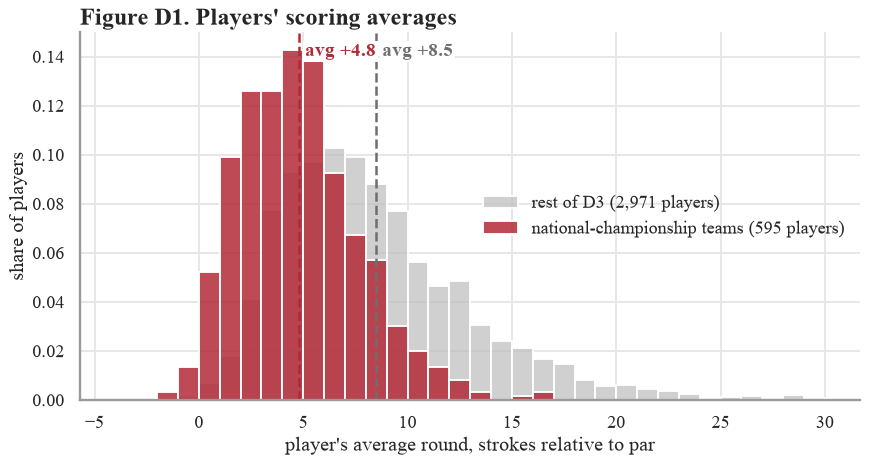

national-championship players: median +4.5, IQR +2.7 to +6.4


In [6]:
# ---- Figure D1: players' scoring averages, national-championship programs vs the rest of D3 ----
def player_avgs(mask):
    r = R_ALL[mask].copy()
    r["to_par"] = holes.loc[np.repeat(mask, N_HOLES), "to_par"].to_numpy().reshape(-1, N_HOLES).sum(1)
    n = r.groupby("player_id")["to_par"].agg(["mean", "size"])
    return n.loc[n["size"] >= MIN_ROUNDS, "mean"]

rest = SCOPE_ALL_D3 & ~is_nat_school
avg_nat, avg_rest = player_avgs(IN_SAMPLE), player_avgs(rest)

fig, ax = plt.subplots(figsize=(10, 5.5))
bins = np.arange(-4, 30.5, 1)
sns.histplot(avg_rest, bins=bins, stat="density", color=NULL_GRAY, alpha=0.7, ax=ax, edgecolor="white",
             label=f"rest of D3 ({len(avg_rest):,} players)")
sns.histplot(avg_nat, bins=bins, stat="density", color=RED, alpha=0.85, ax=ax, edgecolor="white",
             label=f"national-championship teams ({len(avg_nat):,} players)")
for v, c in [(avg_nat.mean(), RED), (avg_rest.mean(), PGA_GRAY)]:
    ax.axvline(v, color=c, lw=2, ls="--")
    ax.text(v + 0.3, ax.get_ylim()[1] * 0.97, f"avg {v:+.1f}", color=c, fontsize=15, fontweight="bold",
            va="top", bbox=dict(fc="white", ec="none", pad=1.5))
ax.set_xlabel("player's average round, strokes relative to par")
ax.set_ylabel("share of players")
ax.set_title("Figure D1. Players' scoring averages")
ax.legend(loc="center right")
plt.tight_layout(); save(fig, "data_D1_player_averages"); plt.show()
print(f"national-championship players: median {avg_nat.median():+.1f}, IQR {avg_nat.quantile(.25):+.1f} to {avg_nat.quantile(.75):+.1f}")

outcome  eagle or better  birdie    par  bogey  double or worse  mean_to_par
par                                                                         
3                  0.000   0.076  0.584  0.288            0.052        0.323
4                  0.001   0.109  0.574  0.254            0.062        0.283
5                  0.016   0.280  0.500  0.156            0.047       -0.048


saved poster/figures/data_D2_score_probabilities.png / .pdf


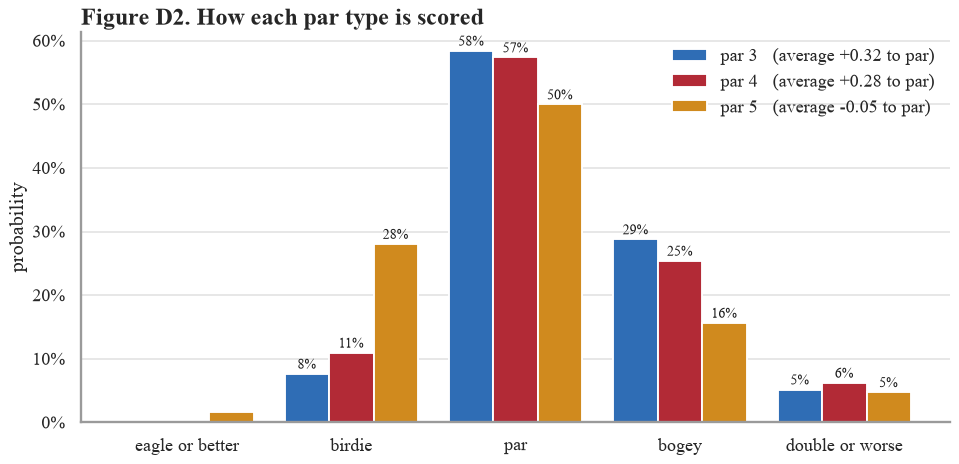

In [7]:
# ---- Figure D2: the probability of each score, by par type ----
OUTCOMES = ["eagle or better", "birdie", "par", "bogey", "double or worse"]
def outcome(tp):
    return np.select([tp <= -2, tp == -1, tp == 0, tp == 1, tp >= 2], OUTCOMES, default="")

d = pd.DataFrame({"par": PAR.ravel(), "to_par": TP.ravel()})
d["outcome"] = outcome(d["to_par"])
probs = (d.groupby("par")["outcome"].value_counts(normalize=True).unstack()[OUTCOMES])
means = d.groupby("par")["to_par"].mean()
PAR_SUMMARY = probs.assign(mean_to_par=means)
print(PAR_SUMMARY.round(3).to_string())

fig, ax = plt.subplots(figsize=(11, 5.5))
x, w = np.arange(len(OUTCOMES)), 0.27
for i, p in enumerate([3, 4, 5]):
    bars = ax.bar(x + (i - 1) * w, probs.loc[p], w, color=PAR_COLORS[p],
                  label=f"par {p}   (average {means[p]:+.2f} to par)", edgecolor="white", linewidth=1.5)
    for xi, v in zip(x + (i - 1) * w, probs.loc[p]):
        if v >= 0.02:
            ax.text(xi, v + 0.008, f"{v:.0%}", ha="center", fontsize=11.5, color=INK)
ax.set_xticks(x); ax.set_xticklabels(OUTCOMES)
ax.set_ylabel("probability"); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Figure D2. How each par type is scored")
ax.legend(loc="upper right"); ax.grid(axis="x", visible=False)
plt.tight_layout(); save(fig, "data_D2_score_probabilities"); plt.show()

saved poster/figures/data_D3_hole_difficulty_by_par.png / .pdf


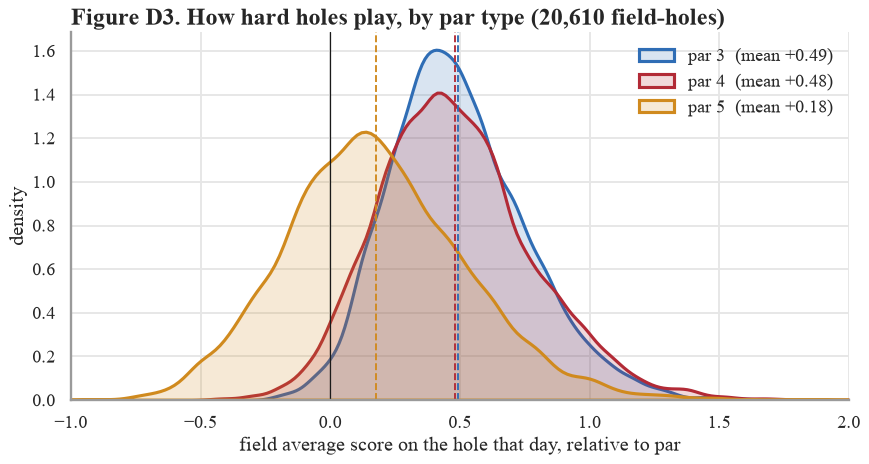

PGA Tour 2014 (paper): par 3 +0.065, par 4 +0.051, par 5 -0.323


In [8]:
# ---- Figure D3: the paper's Figure 1 for D3 (how hard each hole played that day, by par type) ----
fh = pd.DataFrame({"par": PAR.ravel(), "rel": (FAVG_ALL - PAR).ravel(),
                   "key": np.repeat(R[FIELD_KEYS].astype(str).agg("-".join, axis=1).to_numpy(), N_HOLES),
                   "hole": np.tile(np.arange(1, 19), len(R))}).drop_duplicates(["key", "hole"])

fig, ax = plt.subplots(figsize=(10, 5.5))
for p in [3, 4, 5]:
    v = fh.loc[fh["par"] == p, "rel"]
    sns.kdeplot(v, ax=ax, color=PAR_COLORS[p], fill=True, alpha=0.18, lw=2.5, bw_adjust=0.8,
                label=f"par {p}  (mean {v.mean():+.2f})", clip=(-1.5, 2.5))
    ax.axvline(v.mean(), color=PAR_COLORS[p], lw=1.5, ls="--")
ax.axvline(0, color=INK, lw=1)
ax.set_xlim(-1, 2)
ax.set_xlabel("field average score on the hole that day, relative to par")
ax.set_ylabel("density")
ax.set_title(f"Figure D3. How hard holes play, by par type ({len(fh):,} field-holes)")
ax.legend(loc="upper right")
plt.tight_layout(); save(fig, "data_D3_hole_difficulty_by_par"); plt.show()
print("PGA Tour 2014 (paper): par 3 +0.065, par 4 +0.051, par 5 -0.323")

saved poster/figures/data_D4_d3_vs_pga.png / .pdf


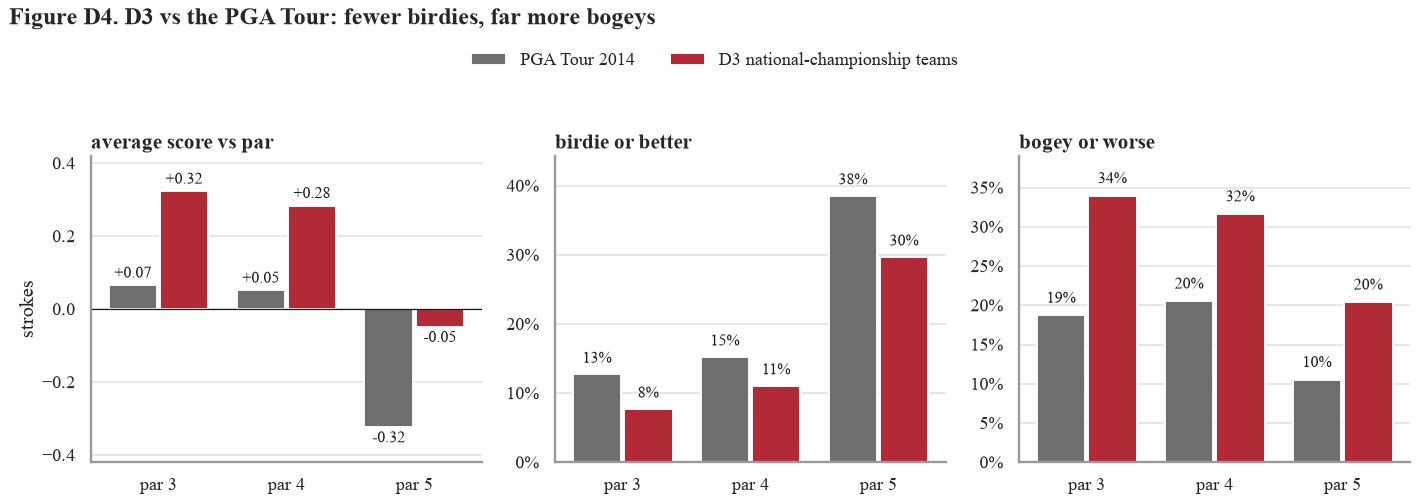

          D3                      PGA              
  avg_to_par    bob    bow avg_to_par    bob    bow
3      0.323  0.077  0.339      0.065  0.127  0.187
4      0.283  0.110  0.316      0.051  0.152  0.205
5     -0.048  0.297  0.204     -0.323  0.385  0.105


In [9]:
# ---- Figure D4: D3 national-championship programs vs the PGA Tour ----
bob = (TP <= -1); bow = (TP >= 1)
D3_RATES = pd.DataFrame({
    "avg_to_par": means,
    "bob": pd.Series(bob.ravel()).groupby(PAR.ravel()).mean(),
    "bow": pd.Series(bow.ravel()).groupby(PAR.ravel()).mean()})
PGA_RATES = pd.DataFrame({k: PGA[k] for k in ["avg_to_par", "bob", "bow"]})

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
panels = [("avg_to_par", "average score vs par", "{:+.2f}"),
          ("bob", "birdie or better", "{:.0%}"), ("bow", "bogey or worse", "{:.0%}")]
for ax, (k, title, fmt) in zip(axes, panels):
    xs = np.arange(3)
    for off, src, col, lab in [(-0.2, PGA_RATES, PGA_GRAY, "PGA Tour 2014"), (0.2, D3_RATES, RED, "D3 national-championship teams")]:
        vals = src.loc[[3, 4, 5], k].to_numpy()
        ax.bar(xs + off, vals, 0.38, color=col, label=lab, edgecolor="white", linewidth=1.5)
        for xi, v in zip(xs + off, vals):
            ax.text(xi, v + (0.012 if v >= 0 else -0.012), fmt.format(v), ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=12.5, color=INK)
    ax.axhline(0, color=INK, lw=1)
    ax.set_xticks(xs); ax.set_xticklabels(["par 3", "par 4", "par 5"])
    ax.set_title(title, fontsize=17); ax.grid(axis="x", visible=False)
    if k != "avg_to_par":
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.margins(y=0.15)
axes[0].set_ylabel("strokes")
handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle("Figure D4. D3 vs the PGA Tour: fewer birdies, far more bogeys", x=0.01, ha="left",
             y=1.09, fontsize=19, fontweight="bold")
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.03))
plt.tight_layout(rect=(0, 0, 1, 0.97)); save(fig, "data_D4_d3_vs_pga"); plt.show()
print(pd.concat({"D3": D3_RATES, "PGA": PGA_RATES}, axis=1).round(3).to_string())

saved poster/figures/data_D5_skill_vs_consistency.png / .pdf


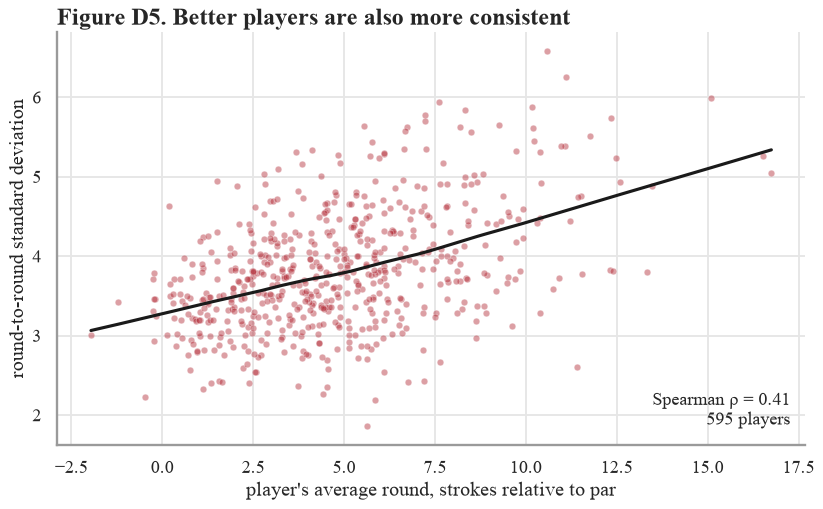

In [10]:
# ---- Figure D5: skill vs consistency (players' average vs round-to-round spread) ----
rt = pd.DataFrame({"player_id": R["player_id"], "to_par": TP.sum(1)})
ps = rt.groupby("player_id")["to_par"].agg(["mean", "std", "size"])
rho = ps[["mean", "std"]].corr(method="spearman").iloc[0, 1]

fig, ax = plt.subplots(figsize=(9.5, 6))
sns.regplot(data=ps, x="mean", y="std", ax=ax, lowess=True,
            scatter_kws=dict(s=28, alpha=0.45, color=RED, edgecolor="white", linewidths=0.5),
            line_kws=dict(color=INK, lw=2.5))
ax.set_xlabel("player's average round, strokes relative to par")
ax.set_ylabel("round-to-round standard deviation")
ax.set_title("Figure D5. Better players are also more consistent")
ax.text(0.98, 0.05, f"Spearman ρ = {rho:.2f}\n{len(ps):,} players", transform=ax.transAxes, ha="right", fontsize=14)
plt.tight_layout(); save(fig, "data_D5_skill_vs_consistency"); plt.show()

In [11]:
# ---- POSTER TEXT: Data box ----
print("POSTER TEXT -----------------------------------------------------------------")
print(f"""Hole-by-hole scores (Clippd) for NCAA Division III men's golf, {GLANCE['seasons']}. Every round
was checked by a tested cleaning pipeline that removes manufactured streaks (nine-hole totals
spread across holes, duplicated or copied cards, fabricated events) and wrong course labels;
{clean_table['kept'] / raw_men:.1%} of men's rounds pass, and rounds are kept or dropped whole. The sample is the
programs that sent a team to the NCAA DIII National Championship ({GLANCE['national-championship teams']}),
using all their stroke-play rounds that season and players with {MIN_ROUNDS}+ rounds:
{GLANCE['players']} players, {GLANCE['rounds']} rounds, {GLANCE['back-to-back hole pairs (same nine)']} back-to-back hole pairs.
These players average {avg_nat.mean():+.1f} per round, against {avg_rest.mean():+.1f} for the rest of D3.""")

POSTER TEXT -----------------------------------------------------------------
Hole-by-hole scores (Clippd) for NCAA Division III men's golf, 2023-24 to 2025-26. Every round
was checked by a tested cleaning pipeline that removes manufactured streaks (nine-hole totals
spread across holes, duplicated or copied cards, fabricated events) and wrong course labels;
98.2% of men's rounds pass, and rounds are kept or dropped whole. The sample is the
programs that sent a team to the NCAA DIII National Championship (109 team-seasons (63 schools)),
using all their stroke-play rounds that season and players with 10+ rounds:
595 players, 15,359 rounds, 245,744 back-to-back hole pairs.
These players average +4.8 per round, against +8.5 for the rest of D3.


## 3. Methods  *(poster box: Methods)*

Four methods, run on the same sample, so they can be compared side by side. Each controls for a
different set of explanations. A method only measures **momentum** if it separates "this hole
affected the next" from three other reasons holes go together:

| explanation | what it means | how it can be removed |
|---|---|---|
| hole difficulty | an easy hole is easy for everyone | strokes gained vs the field |
| skill | good players beat the field on most holes | the player's own baseline |
| volatility | +1 stroke is huge for a steady player, routine for a wild one | divide by the player's own SD |
| **day form** | a good day lifts every hole that day, not just the next one | compare real hole order with order shuffled inside each nine |
| streak-selection bias | in short sequences, P(hit after hit) is biased *down* (Miller & Sanjurjo) | the same shuffle, which keeps each nine's results |

**Which pairs.** There is no tee-time data, and 10th-tee and shotgun starts are common. So
only pairs of holes inside the same nine are used: 1→2 … 8→9 and 10→11 … 17→18, 16 per round.
9→10 and 18→1 may not be consecutive in play.

**Shared machinery** for all four methods is in the next cell: within-nine pairs, the shuffle,
and a bootstrap that resamples whole players for confidence intervals.

In [12]:
def shuffle_index(n_rounds, rng):
    "A random order of the holes inside each nine, independently for each round."
    idx = np.tile(np.arange(N_HOLES), (n_rounds, 1))
    for s in (slice(0, 9), slice(9, 18)):
        idx[:, s] = np.take_along_axis(idx[:, s], rng.random((n_rounds, 9)).argsort(1), 1)
    return idx

reorder = lambda M, idx: np.take_along_axis(M, idx, 1)

def corr_from(s):
    "Pearson r from stacked sums [n, Sa, Sb, Saa, Sbb, Sab] on the last axis."
    n, sa, sb, saa, sbb, sab = np.moveaxis(np.asarray(s, float), -1, 0)
    return (sab - sa * sb / n) / np.sqrt((saa - sa ** 2 / n) * (sbb - sb ** 2 / n))

def lag_sums(M, lag=1):
    "Per-round sums for the within-nine pairs (h, h+lag)."
    a, b = M[:, PAIRS[lag][:, 0]], M[:, PAIRS[lag][:, 1]]
    return np.stack([np.full(len(M), a.shape[1], float), a.sum(1), b.sum(1),
                     (a * a).sum(1), (b * b).sum(1), (a * b).sum(1)], 1)

def to_players(per_round):
    "Sum per-round statistics up to players (the bootstrap unit)."
    out = np.zeros((N_PLAYERS,) + per_round.shape[1:])
    np.add.at(out, PIDX, per_round)
    return out

PLAYERS, PIDX = np.unique(R["player_id"].to_numpy(), return_inverse=True)
N_PLAYERS = len(PLAYERS)
W = np.stack([np.bincount(rng.integers(0, N_PLAYERS, N_PLAYERS), minlength=N_PLAYERS) for _ in range(N_BOOT)])
ci = lambda x, axis=0: np.percentile(x, [2.5, 97.5], axis=axis)
SHUFFLES = [shuffle_index(len(R), rng) for _ in range(N_PERM)]     # the same shuffles are reused by every method

a = SG[:, PAIRS[1][:, 0]].ravel(); b = SG[:, PAIRS[1][:, 1]].ravel()
check("sums-based r matches np.corrcoef", np.isclose(corr_from(lag_sums(SG).sum(0)), np.corrcoef(a, b)[0, 1]))
check("no pair crosses 9->10 or 18->1", not any((h, k) in {(8, 9), (17, 0)} for h, k in PAIRS[1]))
check("a shuffle keeps each nine's holes (only the order changes)",
      (np.sort(reorder(SG, SHUFFLES[0])[:, :9], 1) == np.sort(SG[:, :9], 1)).all())
METHODS = {}      # one summary row per method, compared in section 3.5

[PASS] sums-based r matches np.corrcoef
[PASS] no pair crosses 9->10 or 18->1
[PASS] a shuffle keeps each nine's holes (only the order changes)


### 3.1 Method 1: player z-score by par type *(your method; closest to the abstract)*

1. **Skill** = the player's mean SG on par 3s, par 4s and par 5s separately.
   **Volatility** = the player's SD of SG on each par type.
2. Standardise every hole by the player's own par-type baseline:
   $$z_{ih} = \frac{\text{SG}_{ih} - \overline{\text{SG}}_{i,\,\text{par}(h)}}{s_{i,\,\text{par}(h)}}$$
   The mean and SD come from the player's **other rounds** (leave-round-out), so a hole is
   never part of its own baseline.
3. **Carry-over** = correlation between $z$ on hole *h* and on hole *h + 1*. This is the
   abstract's measure.
4. **Momentum** = carry-over in real order minus carry-over with hole order shuffled inside each
   nine. The shuffle keeps the day and breaks the sequence.

In [13]:
# ---- skill and volatility by par type, leave-round-out ----
def par_z(M):
    Z = np.full(M.shape, np.nan)
    profile = {}
    for p in (3, 4, 5):
        mk = PAR == p
        rn, rs, rss = mk.sum(1), np.where(mk, M, 0).sum(1), np.where(mk, M ** 2, 0).sum(1)
        pn, ps_, pss = to_players(rn[:, None])[:, 0], to_players(rs[:, None])[:, 0], to_players(rss[:, None])[:, 0]
        on, os_, oss = pn[PIDX] - rn, ps_[PIDX] - rs, pss[PIDX] - rss          # player's OTHER rounds
        mu = os_ / on
        sd = np.sqrt((oss - on * mu ** 2) / (on - 1))
        Z = np.where(mk, (M - mu[:, None]) / sd[:, None], Z)
        profile[p] = pd.DataFrame({"skill": ps_ / pn, "volatility": np.sqrt((pss - pn * (ps_ / pn) ** 2) / (pn - 1)),
                                   "holes": pn}, index=PLAYERS)
    return Z, profile

Z, PROFILE = par_z(SG)
check("every hole has a finite par-type z-score", np.isfinite(Z).all())
check("z-scores are standardised (mean ~0, SD ~1)", abs(Z.mean()) < 0.03 and 0.9 < Z.std() < 1.15,
      f"mean {Z.mean():+.3f}, SD {Z.std():.3f}")
print(pd.concat({p: PROFILE[p][["skill", "volatility"]].describe().loc[["mean", "std", "min", "max"]] for p in (3, 4, 5)},
                axis=1).round(3).to_string())

[PASS] every hole has a finite par-type z-score
[PASS] z-scores are standardised (mean ~0, SD ~1)  (mean -0.003, SD 1.019)
          3                 4                 5           
      skill volatility  skill volatility  skill volatility
mean  0.081      0.702  0.097      0.778  0.112      0.851
std   0.123      0.090  0.128      0.090  0.178      0.131
min  -0.523      0.476 -0.534      0.580 -0.725      0.487
max   0.456      1.019  0.449      1.318  0.729      1.414


saved poster/figures/m1a_skill_volatility.png / .pdf


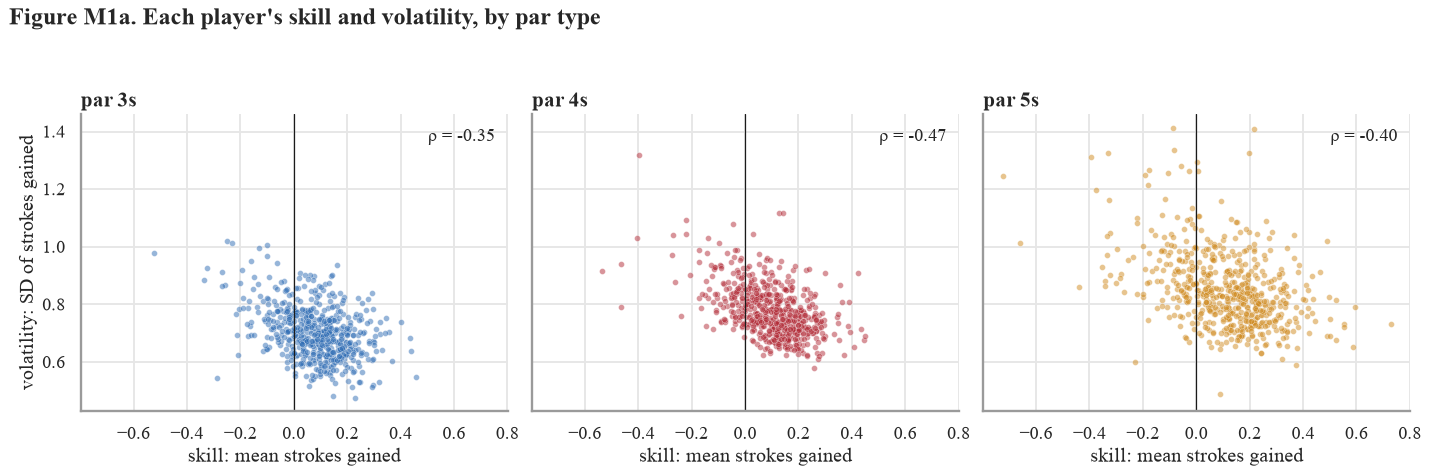

In [14]:
# ---- Figure M1a: every player's skill and volatility, by par type ----
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), sharex=True, sharey=True)
for ax, p in zip(axes, (3, 4, 5)):
    pr = PROFILE[p]
    ax.scatter(pr["skill"], pr["volatility"], s=22, alpha=0.5, color=PAR_COLORS[p], edgecolor="white", linewidths=0.4)
    ax.axvline(0, color=INK, lw=1)
    ax.set_title(f"par {p}s", fontsize=17)
    ax.set_xlabel("skill: mean strokes gained")
    rho = pr[["skill", "volatility"]].corr(method="spearman").iloc[0, 1]
    ax.text(0.97, 0.95, f"ρ = {rho:.2f}", transform=ax.transAxes, ha="right", va="top", fontsize=14)
axes[0].set_ylabel("volatility: SD of strokes gained")
fig.suptitle("Figure M1a. Each player's skill and volatility, by par type", x=0.01, ha="left", y=1.03,
             fontsize=19, fontweight="bold")
plt.tight_layout(); save(fig, "m1a_skill_volatility"); plt.show()

In [15]:
# ---- carry-over: observed, shuffled, momentum ----
s1 = lag_sums(Z)
r_obs = corr_from(s1.sum(0))
r_boot = corr_from(W @ to_players(s1))
r_null = np.array([corr_from(lag_sums(reorder(Z, ix)).sum(0)) for ix in SHUFFLES])
m1 = r_obs - r_null.mean()
m1_ci = ci(r_boot - r_null.mean())
m1_p = (1 + (np.abs(r_null - r_null.mean()) >= abs(m1)).sum()) / (1 + N_PERM)     # two-sided
r_raw = corr_from(lag_sums(SG).sum(0))

print(f"raw strokes gained, lag-1 r          : {r_raw:.4f}")
print(f"par-type z (the abstract's measure)  : {r_obs:.4f}  95% CI {np.round(ci(r_boot), 4)}")
print(f"same, hole order shuffled (day form) : {r_null.mean():.4f}")
print(f"MOMENTUM (z minus shuffled)          : {m1:+.4f}  95% CI {np.round(m1_ci, 4)},  permutation p = {m1_p:.3f}")
print(f"share of the z carry-over that is day form: {r_null.mean() / r_obs:.0%}")
METHODS["1. par-type z-score"] = {
    "measures": "correlation of z, hole h -> h+1", "estimate": m1, "95% CI low": m1_ci[0], "95% CI high": m1_ci[1],
    "p": m1_p, "before day-form control": r_obs, "units": "correlation"}

raw strokes gained, lag-1 r          : 0.0526
par-type z (the abstract's measure)  : 0.0358  95% CI [0.031  0.0404]
same, hole order shuffled (day form) : 0.0364
MOMENTUM (z minus shuffled)          : -0.0006  95% CI [-0.0055  0.004 ],  permutation p = 0.729
share of the z carry-over that is day form: 102%


saved poster/figures/m1b_carryover_vs_shuffled.png / .pdf


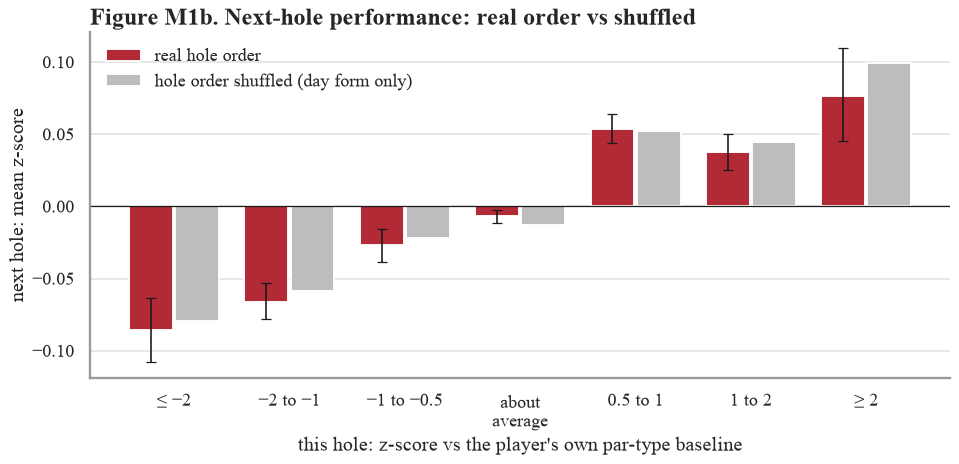

  this-hole z  pairs    real  shuffled  real − shuffled
         ≤ −2   9403 -0.0859   -0.0792          -0.0067
     −2 to −1  28706 -0.0659   -0.0586          -0.0073
   −1 to −0.5  28418 -0.0271   -0.0219          -0.0052
about average 107713 -0.0069   -0.0127           0.0057
     0.5 to 1  40171  0.0538    0.0526           0.0013
       1 to 2  27798  0.0380    0.0444          -0.0064
          ≥ 2   3535  0.0763    0.0996          -0.0234


In [16]:
# ---- Figure M1b: next-hole z by this-hole z, real order vs shuffled ----
EDGES = np.array([-np.inf, -2, -1, -0.5, 0.5, 1, 2, np.inf])
BIN_LABELS = ["≤ −2", "−2 to −1", "−1 to −0.5", "about\naverage", "0.5 to 1", "1 to 2", "≥ 2"]
NB = len(BIN_LABELS)

def bin_sums(M):
    a, b = M[:, PAIRS[1][:, 0]], M[:, PAIRS[1][:, 1]]
    k = np.digitize(a, EDGES[1:-1])
    cnt, tot = np.zeros((len(M), NB)), np.zeros((len(M), NB))
    rr = np.repeat(np.arange(len(M)), a.shape[1])
    np.add.at(cnt, (rr, k.ravel()), 1); np.add.at(tot, (rr, k.ravel()), b.ravel())
    return cnt, tot

cnt, tot = bin_sums(Z)
obs_bins = tot.sum(0) / cnt.sum(0)
null_bins = np.array([(lambda c, t: t.sum(0) / c.sum(0))(*bin_sums(reorder(Z, ix))) for ix in SHUFFLES[:200]])
boot_bins = (W @ to_players(tot)) / (W @ to_players(cnt))
lo, hi = ci(boot_bins)

fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(NB)
ax.bar(x - 0.2, obs_bins, 0.38, color=RED, label="real hole order", edgecolor="white", linewidth=1.5)
ax.errorbar(x - 0.2, obs_bins, yerr=[obs_bins - lo, hi - obs_bins], fmt="none", ecolor=INK, capsize=4, lw=1.3)
ax.bar(x + 0.2, null_bins.mean(0), 0.38, color=NULL_GRAY, label="hole order shuffled (day form only)",
       edgecolor="white", linewidth=1.5)
ax.axhline(0, color=INK, lw=1)
ax.set_xticks(x); ax.set_xticklabels(BIN_LABELS)
ax.set_xlabel("this hole: z-score vs the player's own par-type baseline")
ax.set_ylabel("next hole: mean z-score")
ax.set_title("Figure M1b. Next-hole performance: real order vs shuffled")
ax.legend(loc="upper left"); ax.grid(axis="x", visible=False)
plt.tight_layout(); save(fig, "m1b_carryover_vs_shuffled"); plt.show()
M1_BINS = pd.DataFrame({"this-hole z": [b.replace("\n", " ") for b in BIN_LABELS], "pairs": cnt.sum(0).astype(int),
                        "real": obs_bins, "shuffled": null_bins.mean(0), "real − shuffled": obs_bins - null_bins.mean(0)})
print(M1_BINS.round(4).to_string(index=False))

saved poster/figures/m1c_lag_profile.png / .pdf


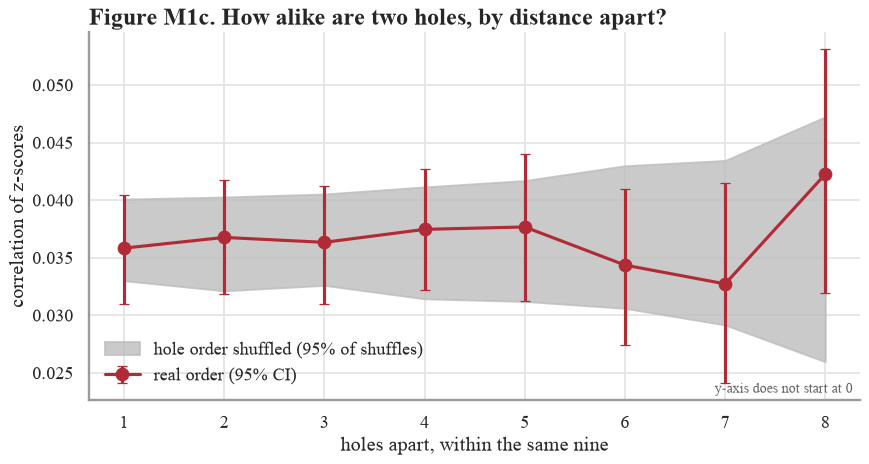

In [17]:
# ---- Figure M1c: the lag profile (momentum = a spike at lag 1; day form = flat) ----
lags = np.arange(1, 9)
prof = np.array([corr_from(lag_sums(Z, L).sum(0)) for L in lags])
prof_boot = np.stack([corr_from(W @ to_players(lag_sums(Z, L))) for L in lags], 1)
null_prof = np.array([[corr_from(lag_sums(reorder(Z, ix), L).sum(0)) for L in lags] for ix in SHUFFLES[:200]])

fig, ax = plt.subplots(figsize=(10, 5.5))
band = ci(null_prof)
ax.fill_between(lags, band[0], band[1], color=NULL_GRAY, alpha=0.8, label="hole order shuffled (95% of shuffles)")
plo, phi = ci(prof_boot)
ax.errorbar(lags, prof, yerr=[prof - plo, phi - prof], color=RED, marker="o", ms=10, capsize=4, lw=2.5,
            label="real order (95% CI)")
ax.set_xticks(lags)
ax.set_xlabel("holes apart, within the same nine")
ax.set_ylabel("correlation of z-scores")
ax.set_title("Figure M1c. How alike are two holes, by distance apart?")
ax.legend(loc="lower left")
ax.text(0.99, 0.02, "y-axis does not start at 0", transform=ax.transAxes, ha="right", fontsize=11, color=MUTED)
plt.tight_layout(); save(fig, "m1c_lag_profile"); plt.show()

### 3.2 Method 2: mixed-effects logistic regression *(Elmore & Urbaczewski replication)*

The PGA Tour paper's model, fitted to D3 with R's `lme4::glmer`, for birdie-or-better (BoB) and
bogey-or-worse (BoW) separately:

$$\operatorname{logit} P(\text{BoW}_{ih}) = \beta_0 + \beta_1\,\text{difficulty}_{ih} + \beta_2\,\text{BoW}_{i,h-1} + \beta_3\,\text{par4} + \beta_4\,\text{par5} + u_i$$

`difficulty` is the leave-one-out field average on the hole that day, minus par, and $u_i$ is a
player random effect (skill). The cold-hand test is $\beta_2 > 0$. On the PGA Tour the paper
found $\beta_2 = 0.093$ (SE 0.021) for BoW, and no BoB effect.

Two versions are fitted:

* **Paper's model**, exactly as above. This is the like-for-like comparison with the PGA Tour.
* **Extended model**, which adds a **player-round** random effect (day form) and the
  **previous hole's difficulty**. A birdie is likelier on an easy hole, and courses tend to
  follow an easy hole with a hard one.

Each is also refitted on 10 shuffled-order copies of the data. A logistic model on 16-hole
rounds has a small-sample bias of its own: the Miller–Sanjurjo effect shows up here too, and
the extended model's raw coefficient is strongly affected by it. **Momentum = real-order
$\beta_2$ − the shuffled-order average.**

In [18]:
def pair_table(idx=None):
    "One row per within-nine pair, in real order or with hole order shuffled by `idx`."
    tp, par, dif = (TP, PAR, DIFF) if idx is None else (reorder(TP, idx), reorder(PAR, idx), reorder(DIFF, idx))
    a, b = PAIRS[1][:, 0], PAIRS[1][:, 1]
    k = len(a)
    return pd.DataFrame({
        "player_id": np.repeat(R["player_id"].to_numpy(), k), "round_id": np.repeat(R["round_id"].to_numpy(), k),
        "bob": (tp[:, b] <= -1).ravel().astype(np.int8), "bow": (tp[:, b] >= 1).ravel().astype(np.int8),
        "prev_bob": (tp[:, a] <= -1).ravel().astype(np.int8), "prev_bow": (tp[:, a] >= 1).ravel().astype(np.int8),
        "difficulty": dif[:, b].ravel(), "prev_difficulty": dif[:, a].ravel(),
        "par4": (par[:, b] == 4).ravel().astype(np.int8), "par5": (par[:, b] == 5).ravel().astype(np.int8)})

M2_DIR = CLEAN_DIR / "poster_m2"
M2_DIR.mkdir(exist_ok=True)
for old in M2_DIR.glob("*.parquet"):
    old.unlink()
N_M2_SHUFFLES = 10
pair_table().to_parquet(M2_DIR / "real.parquet", index=False)
for j in range(N_M2_SHUFFLES):
    pair_table(SHUFFLES[j]).to_parquet(M2_DIR / f"shuffled_{j:02d}.parquet", index=False)

R_SCRIPT = r"""
suppressPackageStartupMessages({library(lme4); library(arrow); library(data.table)})
dir <- commandArgs(TRUE)[1]
ctrl <- glmerControl(optimizer = "bobyqa", calc.derivs = FALSE)
specs <- c(paper    = "%1$s ~ difficulty + prev_%1$s + par4 + par5 + (1 | player)",
           extended = "%1$s ~ difficulty + prev_difficulty + prev_%1$s + par4 + par5 + (1 | player) + (1 | player_round)")
out <- list()
for (f in sort(list.files(dir, pattern = "^(real|shuffled_[0-9]+)[.]parquet$"))) {
  d <- as.data.table(read_parquet(file.path(dir, f)))
  d[, `:=`(player = factor(player_id), player_round = factor(round_id))]
  for (k in c("bob", "bow")) for (sp in names(specs)) {
    m <- glmer(as.formula(sprintf(specs[[sp]], k)), data = d, family = binomial, nAGQ = 0, control = ctrl)
    s <- summary(m)$coefficients
    out[[length(out) + 1]] <- data.table(data = sub("[.]parquet$", "", f), outcome = k, spec = sp,
                                         term = rownames(s), estimate = s[, 1], se = s[, 2])
  }
}
fwrite(rbindlist(out), file.path(dir, "fixed_effects.csv"))
"""
(M2_DIR / "fit.R").write_text(R_SCRIPT)
res = subprocess.run(["Rscript", str(M2_DIR / "fit.R"), str(M2_DIR)], capture_output=True, text=True)
print(res.stderr[-2000:] if res.returncode else f"R fits finished: 2 outcomes x 2 models x {1 + N_M2_SHUFFLES} datasets")
check("R mixed models ran", res.returncode == 0)
FE = pd.read_csv(M2_DIR / "fixed_effects.csv")
FE["order"] = np.where(FE["data"] == "real", "real", "shuffled")
print("paper's model, real order (compare with the paper's Tables 2 and 3):")
print(FE[(FE["data"] == "real") & (FE["spec"] == "paper")]
      .pivot_table(index="term", columns="outcome", values="estimate").round(3).to_string())

R fits finished: 2 outcomes x 2 models x 11 datasets
[PASS] R mixed models ran
paper's model, real order (compare with the paper's Tables 2 and 3):
outcome        bob    bow
term                     
(Intercept) -1.873 -1.319
difficulty  -1.801  1.578
par4         0.366 -0.087
par5         1.056 -0.241
prev_bob    -0.041    NaN
prev_bow       NaN  0.080


                  estimate     se  shuffled mean  shuffled sd  momentum  momentum se  95% CI low  95% CI high
outcome spec                                                                                                 
bob     paper       -0.041  0.018          0.017        0.017    -0.058        0.019      -0.095       -0.021
        extended    -0.031  0.019          0.033        0.023    -0.063        0.020      -0.102       -0.024
bow     paper        0.080  0.010          0.073        0.005     0.006        0.010      -0.013        0.026
        extended     0.037  0.010          0.027        0.003     0.009        0.010      -0.011        0.029


saved poster/figures/m2_mixed_model.png / .pdf


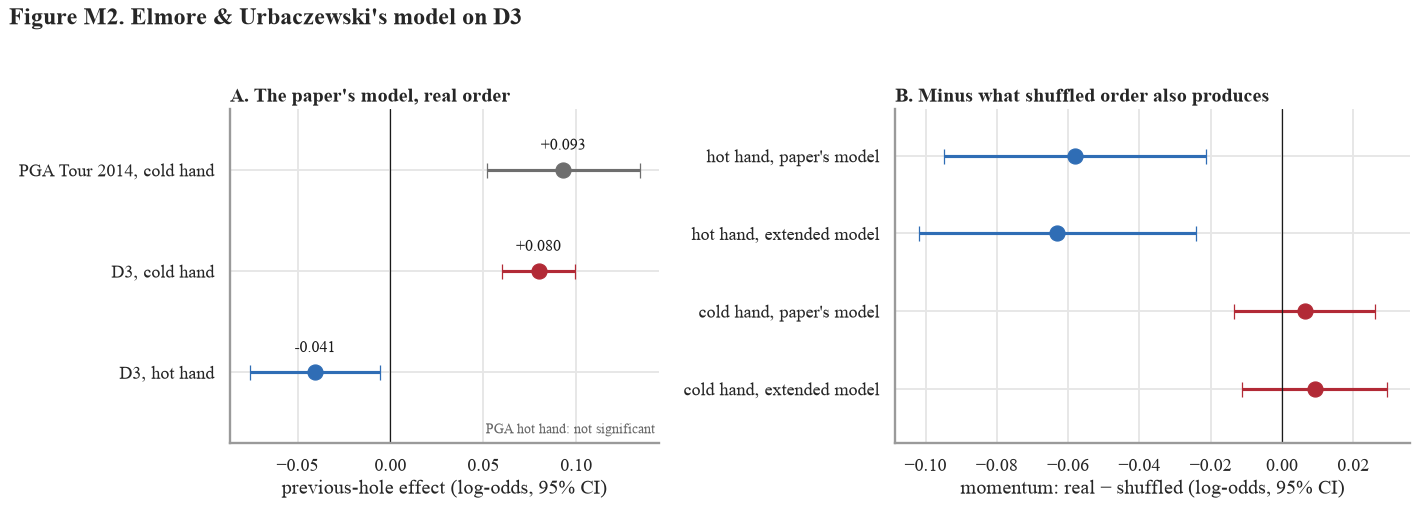

In [19]:
# ---- previous-hole coefficient: real vs shuffled, and momentum ----
prev = FE[FE["term"].isin(["prev_bob", "prev_bow"])]
real = prev[prev["order"] == "real"].set_index(["outcome", "spec"])[["estimate", "se"]]
shuf = prev[prev["order"] == "shuffled"].groupby(["outcome", "spec"])["estimate"].agg(["mean", "std"])
M2 = real.join(shuf.rename(columns={"mean": "shuffled mean", "std": "shuffled sd"}))
M2["momentum"] = M2["estimate"] - M2["shuffled mean"]
M2["momentum se"] = np.sqrt(M2["se"] ** 2 + M2["shuffled sd"] ** 2 / N_M2_SHUFFLES)
M2["95% CI low"] = M2["momentum"] - 1.96 * M2["momentum se"]
M2["95% CI high"] = M2["momentum"] + 1.96 * M2["momentum se"]
print(M2.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axes[0]                       # A: the paper's exact model, D3 next to the PGA Tour
rows = [("PGA Tour 2014, cold hand", *PGA["prev_bow_logodds"], PGA_GRAY),
        ("D3, cold hand", M2.loc[("bow", "paper"), "estimate"], M2.loc[("bow", "paper"), "se"], RED),
        ("D3, hot hand", M2.loc[("bob", "paper"), "estimate"], M2.loc[("bob", "paper"), "se"], BLUE)]
y = np.arange(len(rows))[::-1]
for yi, (lab, est, se, col) in zip(y, rows):
    ax.errorbar(est, yi, xerr=1.96 * se, fmt="o", color=col, ms=12, capsize=6, lw=2.5)
    ax.text(est, yi + 0.2, f"{est:+.3f}", ha="center", fontsize=13, color=INK)
ax.axvline(0, color=INK, lw=1)
ax.set_yticks(y); ax.set_yticklabels([r[0] for r in rows])
ax.set_ylim(-0.7, len(rows) - 0.4)
ax.set_xlabel("previous-hole effect (log-odds, 95% CI)")
ax.set_title("A. The paper's model, real order", fontsize=16)
ax.text(0.99, 0.02, "PGA hot hand: not significant", transform=ax.transAxes, ha="right", va="bottom",
        fontsize=11.5, color=MUTED)

ax = axes[1]                       # B: momentum after subtracting the shuffled-order coefficient
rows = []
for k, name, col in [("bob", "hot hand", BLUE), ("bow", "cold hand", RED)]:
    for sp, lab in [("paper", "paper's model"), ("extended", "extended model")]:
        r_ = M2.loc[(k, sp)]
        rows.append((f"{name}, {lab}", r_["momentum"], r_["95% CI low"], r_["95% CI high"], col))
y = np.arange(len(rows))[::-1]
for yi, (lab, est, lo_, hi_, col) in zip(y, rows):
    ax.errorbar(est, yi, xerr=[[est - lo_], [hi_ - est]], fmt="o", color=col, ms=12, capsize=6, lw=2.5)
ax.axvline(0, color=INK, lw=1)
ax.set_yticks(y); ax.set_yticklabels([r[0] for r in rows])
ax.set_ylim(-0.7, len(rows) - 0.4)
ax.set_xlabel("momentum: real − shuffled (log-odds, 95% CI)")
ax.set_title("B. Minus what shuffled order also produces", fontsize=16)
fig.suptitle("Figure M2. Elmore & Urbaczewski's model on D3", x=0.01, ha="left", y=1.02, fontsize=19, fontweight="bold")
plt.tight_layout(); save(fig, "m2_mixed_model"); plt.show()

for k in ("bob", "bow"):
    r_ = M2.loc[(k, "extended")]
    METHODS[f"2. mixed model ({k.upper()})"] = {
        "measures": f"prev-hole {k.upper()} log-odds, extended model, real minus shuffled",
        "estimate": r_["momentum"], "95% CI low": r_["95% CI low"], "95% CI high": r_["95% CI high"],
        "p": np.nan, "before day-form control": M2.loc[(k, "paper"), "estimate"], "units": "log-odds"}

### 3.3 Method 3: streak test with the Miller–Sanjurjo correction

This is the hot-hand literature's own test. It compares the chance of a birdie (or bogey) right
after one with the chance after anything else:

$$D = P(\text{BoB}_h \mid \text{BoB}_{h-1}) - P(\text{BoB}_h \mid \text{no BoB}_{h-1})$$

Gilovich et al. compared $D$ with 0. Miller & Sanjurjo (2018) showed that in short sequences
$D$ is biased **below** 0 even with no hot hand. The null here is the same statistic on each
round's own nine holes in shuffled order. That keeps each player's number of birdies per nine
(skill *and* day form) and automatically includes the bias.

**One adjustment, for course design.** Holes are not interchangeable: par 5s give most of the
birdies and are rarely back to back. So a birdie is usually followed by a harder hole, in real
order but not after a shuffle. A raw $D$ against the shuffle would read that course design as an
"anti-hot hand". So the next hole's result is measured against the rest of the field's rate on
that hole that day:

$$D = \overline{(y_h - p_h)}\,\big|_{\text{BoB}_{h-1}} \;-\; \overline{(y_h - p_h)}\,\big|_{\text{no BoB}_{h-1}}$$

where $p_h$ is the field's (leave-one-out) BoB rate on hole $h$ that day **plus the player's
own excess on that par type** (from their other rounds, as in Method 1). The second part is
needed because good players beat the field mostly on par 5s, and par 5s are never back to back in
real order but can be after a shuffle. The raw, unadjusted $D$ is printed too, to show how large
the course-design artifact is.

saved poster/figures/m3_streak_test.png / .pdf


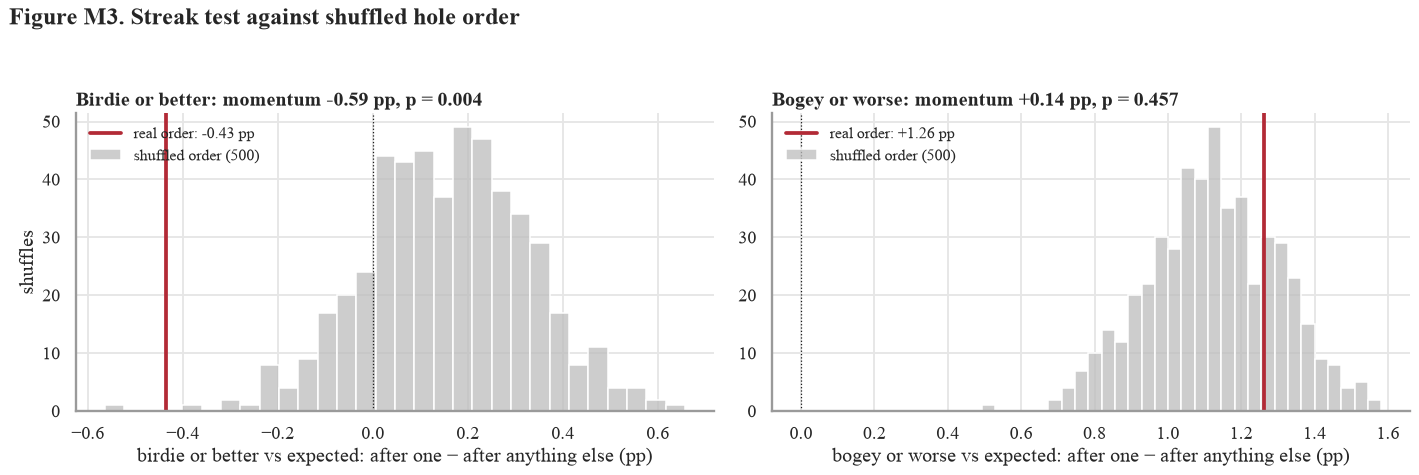

     raw D (real − shuffled), course-design artifact included  D observed  D shuffled (bias + skill + day form)  momentum  95% CI low  95% CI high  permutation p
bob                                                   -0.0138     -0.0043                                0.0016   -0.0059     -0.0098      -0.0022         0.0040
bow                                                    0.0001      0.0126                                0.0112    0.0014     -0.0029       0.0053         0.4571

The shuffled D is the naive test's baseline: it is not 0, because skill, day form and the Miller–Sanjurjo bias all move it.


In [20]:
def player_par_excess(E):
    "Player's mean of E on each par type, from their OTHER rounds (leave-round-out), as a rounds x 18 matrix."
    out = np.zeros(E.shape)
    for p in (3, 4, 5):
        mk = PAR == p
        rn, rs = mk.sum(1), np.where(mk, E, 0).sum(1)
        pn, ps_ = to_players(rn[:, None])[:, 0], to_players(rs[:, None])[:, 0]
        out = np.where(mk, ((ps_[PIDX] - rs) / (pn[PIDX] - rn))[:, None], out)
    return out

EXPECTED = {}
for k in ("bob", "bow"):
    y_ = ((TP <= -1) if k == "bob" else (TP >= 1)).astype(float)
    EXPECTED[k] = RATE[k] + player_par_excess(y_ - RATE[k])

def streak_D(tp, rate, kind, adjust=True):
    """Next-hole excess over the field rate after a hit, minus the same after a non-hit (within-nine pairs).
    With adjust=False it is the raw P(y | prev y) - P(y | not prev y). Also returns per-round sums for the bootstrap."""
    y = ((tp <= -1) if kind == "bob" else (tp >= 1)).astype(float)
    e = y - rate if adjust else y
    a, b = y[:, PAIRS[1][:, 0]].astype(bool), e[:, PAIRS[1][:, 1]]
    per_round = np.stack([a.sum(1), np.where(a, b, 0).sum(1), (~a).sum(1), np.where(~a, b, 0).sum(1)], 1)
    t = per_round.sum(0)
    return t[1] / t[0] - t[3] / t[2], per_round

M3 = {}
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
for ax, kind, name in [(axes[0], "bob", "birdie or better"), (axes[1], "bow", "bogey or worse")]:
    d_obs, pr = streak_D(TP, EXPECTED[kind], kind)
    d_null = np.array([streak_D(reorder(TP, ix), reorder(EXPECTED[kind], ix), kind)[0] for ix in SHUFFLES])
    raw_obs = streak_D(TP, RATE[kind], kind, adjust=False)[0]
    raw_null = np.mean([streak_D(reorder(TP, ix), reorder(RATE[kind], ix), kind, adjust=False)[0] for ix in SHUFFLES[:100]])
    bt = W @ to_players(pr)
    d_boot = bt[:, 1] / bt[:, 0] - bt[:, 3] / bt[:, 2]
    p = (1 + (np.abs(d_null - d_null.mean()) >= abs(d_obs - d_null.mean())).sum()) / (1 + N_PERM)   # two-sided
    M3[kind] = {"raw D (real − shuffled), course-design artifact included": raw_obs - raw_null,
                "D observed": d_obs, "D shuffled (bias + skill + day form)": d_null.mean(),
                "momentum": d_obs - d_null.mean(), "95% CI low": ci(d_boot - d_null.mean())[0],
                "95% CI high": ci(d_boot - d_null.mean())[1], "permutation p": p}
    sns.histplot(d_null * 100, ax=ax, color=NULL_GRAY, bins=30, edgecolor="white", label="shuffled order (500)")
    ax.axvline(d_obs * 100, color=RED, lw=3, label=f"real order: {d_obs * 100:+.2f} pp")
    ax.axvline(0, color=INK, lw=1, ls=":")
    ax.set_xlabel(f"{name} vs expected: after one − after anything else (pp)")
    ax.set_title(f"{name.capitalize()}: momentum {100 * (d_obs - d_null.mean()):+.2f} pp, p = {p:.3f}", fontsize=16)
    ax.legend(loc="upper left", fontsize=12.5)
axes[0].set_ylabel("shuffles"); axes[1].set_ylabel("")
fig.suptitle("Figure M3. Streak test against shuffled hole order", x=0.01, ha="left", y=1.03, fontsize=19, fontweight="bold")
plt.tight_layout(); save(fig, "m3_streak_test"); plt.show()
M3 = pd.DataFrame(M3).T
print(M3.round(4).to_string())
print("\nThe shuffled D is the naive test's baseline: it is not 0, because skill, day form and the "
      "Miller–Sanjurjo bias all move it.")
for kind in ("bob", "bow"):
    METHODS[f"3. streak test ({kind.upper()})"] = {
        "measures": f"P({kind.upper()} | prev {kind.upper()}) − P({kind.upper()} | not), real minus shuffled",
        "estimate": M3.loc[kind, "momentum"], "95% CI low": M3.loc[kind, "95% CI low"],
        "95% CI high": M3.loc[kind, "95% CI high"], "p": M3.loc[kind, "permutation p"],
        "before day-form control": M3.loc[kind, "D observed"], "units": "probability"}

### 3.4 Method 4: what the previous hole costs, in strokes *(fixed-effects regression)*

The most interpretable version of the question for a coach: **after a birdie, a bogey or a
double, how many strokes does the player gain or lose on the next hole?**

$$\text{SG}_{i,h+1} = \beta_1\,\text{birdie+}_{ih} + \beta_2\,\text{bogey}_{ih} + \beta_3\,\text{double+}_{ih} + \alpha_{i,\text{round}} + \varepsilon$$

* Par on the previous hole is the reference.
* $\alpha_{i,\text{round}}$ is a fixed effect for each **player-round**, so each player's day is
  its own baseline. That removes skill and day form together.
* Fixed effects with 16 holes per round are biased (Nickell bias). As in every method here, the
  same regression on shuffled order measures that bias, and momentum is real minus shuffled.

next-hole strokes gained, relative to after a par:
                          real order  shuffled order  momentum (strokes)  95% CI low  95% CI high  p (shuffle)
after a birdie or better     -0.0604         -0.0518             -0.0086     -0.0175       0.0005       0.0698
after a bogey                 0.0452          0.0514             -0.0061     -0.0136       0.0023       0.0897
after a double or worse       0.1070          0.1176             -0.0106     -0.0244       0.0036       0.0930
saved poster/figures/m4_strokes_after.png / .pdf


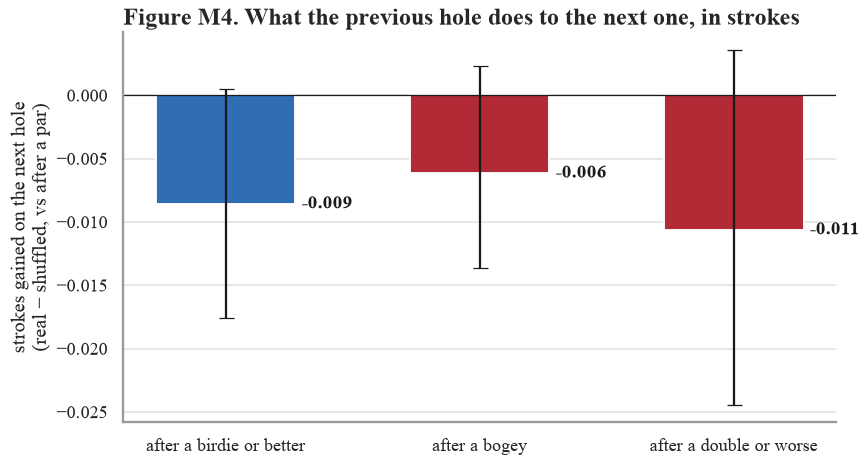

In [21]:
def fe_parts(sg, tp):
    "Within-round demeaned X'X and X'y per round, for prev-hole birdie+/bogey/double+ -> next-hole SG."
    a, b = PAIRS[1][:, 0], PAIRS[1][:, 1]
    prev = tp[:, a]
    X = np.stack([(prev <= -1), (prev == 1), (prev >= 2)], -1).astype(float)     # rounds x 16 x 3
    y = sg[:, b]
    X = X - X.mean(1, keepdims=True); y = y - y.mean(1, keepdims=True)
    return np.einsum("rpi,rpj->rij", X, X), np.einsum("rpi,rp->ri", X, y)

def fe_beta(XtX, Xty):
    return np.linalg.solve(XtX, Xty[..., None])[..., 0]

XtX, Xty = fe_parts(SG, TP)
b_obs = fe_beta(XtX.sum(0), Xty.sum(0))
b_null = np.array([fe_beta(*(v.sum(0) for v in fe_parts(reorder(SG, ix), reorder(TP, ix)))) for ix in SHUFFLES[:300]])
PX, PY = to_players(XtX), to_players(Xty)
b_boot = fe_beta(np.einsum("bp,pij->bij", W, PX), W @ PY)
mom, mom_ci = b_obs - b_null.mean(0), ci(b_boot - b_null.mean(0))
TERMS = ["after a birdie or better", "after a bogey", "after a double or worse"]
M4 = pd.DataFrame({"real order": b_obs, "shuffled order": b_null.mean(0), "momentum (strokes)": mom,
                   "95% CI low": mom_ci[0], "95% CI high": mom_ci[1],
                   "p (shuffle)": [(1 + (np.abs(b_null[:, j] - b_null[:, j].mean()) >= abs(mom[j])).sum()) / (1 + len(b_null))
                                   for j in range(3)]}, index=TERMS)
print("next-hole strokes gained, relative to after a par:")
print(M4.round(4).to_string())

fig, ax = plt.subplots(figsize=(10, 5.5))
cols = [BLUE, RED, RED]
x = np.arange(3)
ax.bar(x, mom, 0.55, color=cols, edgecolor="white", linewidth=1.5)
ax.errorbar(x, mom, yerr=[mom - mom_ci[0], mom_ci[1] - mom], fmt="none", ecolor=INK, capsize=6, lw=1.8)
for xi, v in zip(x, mom):
    ax.text(xi + 0.3, v, f"{v:+.3f}", va="center", fontsize=15, color=INK, fontweight="bold")
ax.axhline(0, color=INK, lw=1)
ax.set_xticks(x); ax.set_xticklabels(TERMS)
ax.set_ylabel("strokes gained on the next hole\n(real − shuffled, vs after a par)")
ax.set_title("Figure M4. What the previous hole does to the next one, in strokes")
ax.grid(axis="x", visible=False)
plt.tight_layout(); save(fig, "m4_strokes_after"); plt.show()
for t, short in zip(TERMS, ["birdie+", "bogey", "double+"]):
    METHODS[f"4. strokes after {short}"] = {
        "measures": f"next-hole SG {t}, player-round fixed effects, real minus shuffled",
        "estimate": M4.loc[t, "momentum (strokes)"], "95% CI low": M4.loc[t, "95% CI low"],
        "95% CI high": M4.loc[t, "95% CI high"], "p": M4.loc[t, "p (shuffle)"],
        "before day-form control": np.nan, "units": "strokes"}

### 3.5 The four methods side by side

| | 1. par-type z | 2. mixed model | 3. streak test | 4. strokes after |
|---|---|---|---|---|
| closest to | **your abstract** | Elmore & Urbaczewski (PGA) | Gilovich / Miller & Sanjurjo | coaching question |
| outcome | strokes gained (continuous) | BoB / BoW (yes/no) | BoB / BoW (yes/no) | strokes gained |
| hole difficulty | field | covariate | — (shuffle keeps holes) | field |
| skill | own baseline | player effect | shuffle | player-round FE |
| volatility | divide by own SD | — | — | — |
| day form | shuffle | player-round effect + shuffle | shuffle | player-round FE + shuffle |
| streak-selection bias | shuffle | shuffle | shuffle | shuffle |
| hot vs cold separately | by bin (M1b) | yes | yes | yes |
| units a judge reads easily | correlation | log-odds | percentage points | **strokes** |

In [22]:
CMP = pd.DataFrame(METHODS).T
CMP["CI excludes 0"] = (CMP["95% CI low"] > 0) | (CMP["95% CI high"] < 0)
print(CMP[["units", "before day-form control", "estimate", "95% CI low", "95% CI high", "p", "CI excludes 0"]]
      .to_string(float_format=lambda v: f"{v:+.4f}"))

tests = pd.DataFrame(TESTS)
print(f"\n{int(tests['passed'].sum())} of {len(tests)} tests passed.")

                                units before day-form control estimate 95% CI low 95% CI high       p  CI excludes 0
1. par-type z-score       correlation                 +0.0358  -0.0006    -0.0055     +0.0040 +0.7285          False
2. mixed model (BOB)         log-odds                 -0.0406  -0.0631    -0.1020     -0.0242     NaN           True
2. mixed model (BOW)         log-odds                 +0.0797  +0.0091    -0.0112     +0.0294     NaN          False
3. streak test (BOB)      probability                 -0.0043  -0.0059    -0.0098     -0.0022 +0.0040           True
3. streak test (BOW)      probability                 +0.0126  +0.0014    -0.0029     +0.0053 +0.4571          False
4. strokes after birdie+      strokes                     NaN  -0.0086    -0.0175     +0.0005 +0.0698          False
4. strokes after bogey        strokes                     NaN  -0.0061    -0.0136     +0.0023 +0.0897          False
4. strokes after double+      strokes                     NaN  -

---
## ⏸ Pause: choose the methods

Read section 3 and pick what the poster will carry. Section 4 (Analysis & Results, Conclusion,
Future, Sources) gets written around that choice.

The question to settle first is what the poster's headline result is (the one figure a passerby
reads). The comparison table above gives each method's momentum estimate after the day-form
control.